### Radio Lab 3

In [1]:
# use argrelmax and angrelmin to find peaks and dips
# argrelmax(power, axis = 0, order = 75)[0]

Step 1: visibility from 2 gaussians
* Goal: estimate angular size and shape of the Sun
* Sun radiates a lot in radio higher frequencies (GHz)
* Can find thesis online from person that built interferometer
* Extra path length can be found with equation
* Sinusoidal pattern is <Vtot^2>
* Plot visibility over baseline to find shape and size of sun with 8 element interferometer - can vary length of baselines
* Fringe width: width of 1 gaussian shaped peake in the pattern from the data.
* AIM: visibility vs baseline and fit this to estimate ang size of sun. changing length of baselines is important to estimate Sun size
* Flag peaks as RFI and remove them, then plot power over time and fit 1 Gaussian to all the top peaks and then 1 Gaussian to the bottom peaks: respectively Pmin and Pmax, from those get visibility

Step 2: visibility vs baseline
* Use fringes to estimate baseline length: average 2 gaussians and subtract it from dataset. From earths rotation around the sun turn time into angle.
* We want to know baseline B, find average Wfringe (fringe width) from multiple peaks, thetaFWHM and D from dish, and calcualte baseline as a function of wavelength. Plot visibility vs baseline. Check against different situations, check if Sun is more like a square, a circle, or a ring. Use chi-squared for example to check best fit parameter quantities.

In [2]:
#plot the data
#convert the data
#time in degs
#in baseline formula, use fwhm

In [3]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.pyplot import figure,show
from scipy.optimize import curve_fit
from scipy.signal import argrelmax
from scipy.signal import argrelmin
from scipy.special import jv

In [4]:
baseline_A = np.loadtxt(f'baseline_A.txt',comments="#")
time_A = np.array(baseline_A[:,0])
time_A = time_A*(360/(3600*24))
power_A = np.array(baseline_A[:,1])
power_A = 10**(power_A/10) #convert to mW

baseline_B = np.loadtxt(f'baseline_B.txt',comments="#")
time_B = np.array(baseline_B[:,0])
time_B = time_B*(360/(3600*24))
power_B = np.array(baseline_B[:,1])
power_B = 10**(power_B/10) #convert to mW

baseline_C = np.loadtxt(f'baseline_C.txt',comments="#")
time_C = np.array(baseline_C[:,0])
time_C = time_C*(360/(3600*24))
power_C = np.array(baseline_C[:,1])
power_C = 10**(power_C/10) #convert to mW

baseline_D = np.loadtxt(f'baseline_D.txt',comments="#")
time_D = np.array(baseline_D[:,0])
time_D = time_D*(360/(3600*24))
power_D = np.array(baseline_D[:,1])
power_D = 10**(power_D/10) #convert to mW

baseline_E = np.loadtxt(f'baseline_E.txt',comments="#")
time_E = np.array(baseline_E[:,0])
time_E = time_E*(360/(3600*24))
power_E = np.array(baseline_E[:,1])
power_E = 10**(power_E/10) #convert to mW

baseline_F = np.loadtxt(f'baseline_F.txt',comments="#")
time_F = np.array(baseline_F[:,0])
time_F = time_F*(360/(3600*24))
power_F = np.array(baseline_F[:,1])
power_F = 10**(power_F/10) #convert to mW

baseline_G = np.loadtxt(f'baseline_G.txt',comments="#")
time_G = np.array(baseline_G[:,0])
time_G = time_G*(360/(3600*24))
power_G_raw = np.array(baseline_G[:,1])
power_G_lin = 10**(power_G_raw/10) #convert to mW
threshold = 8.7e-5
power_G = np.where(power_G_lin < threshold, power_G_lin, np.nan) #mask bad data

baseline_H = np.loadtxt(f'baseline_H.txt',comments="#")
time_H = np.array(baseline_H[:,0])
time_H = time_H*(360/(3600*24))
power_H = np.array(baseline_H[:,1])
power_H = 10**(power_H/10) #convert to mW

baselines = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
times = [time_A, time_B, time_C, time_D, time_E, time_F, time_G, time_H]
powers = [power_A, power_B, power_C, power_D, power_E, power_F, power_G, power_H]

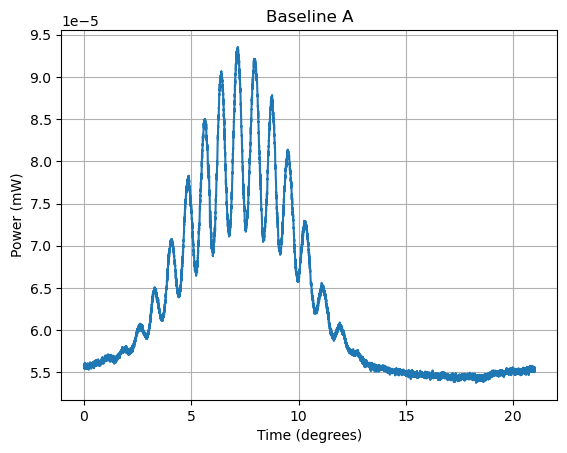

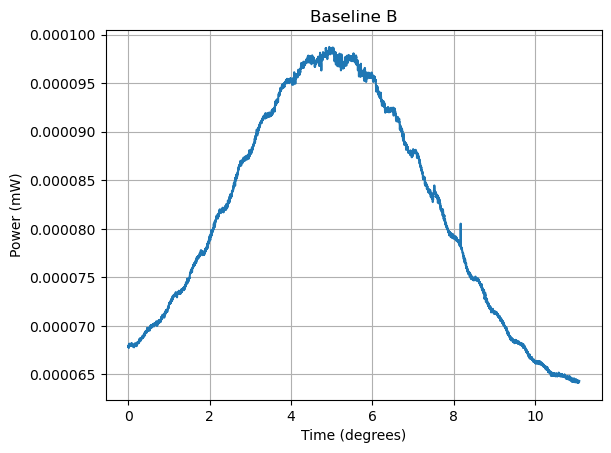

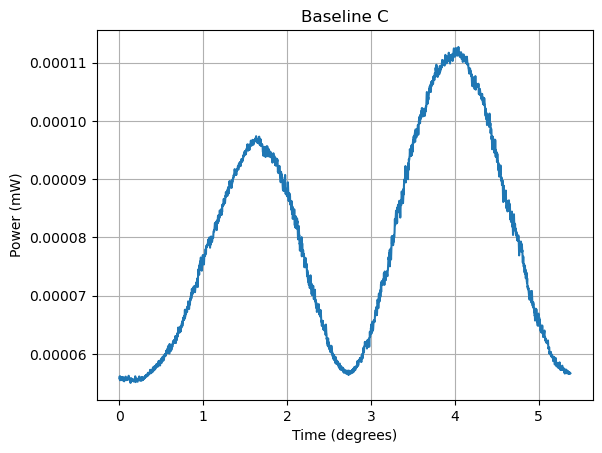

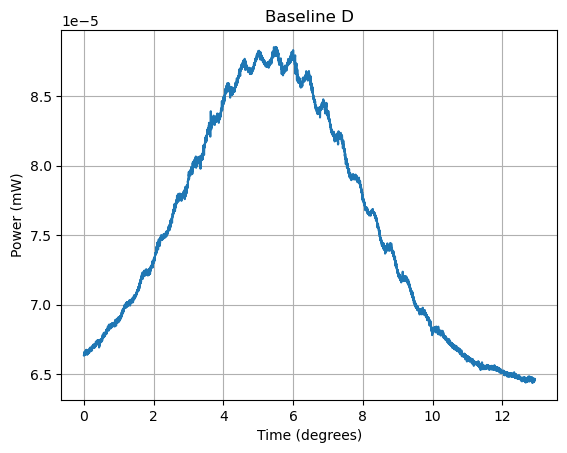

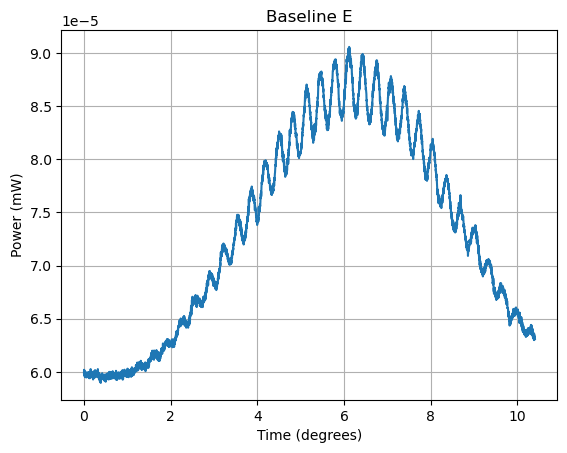

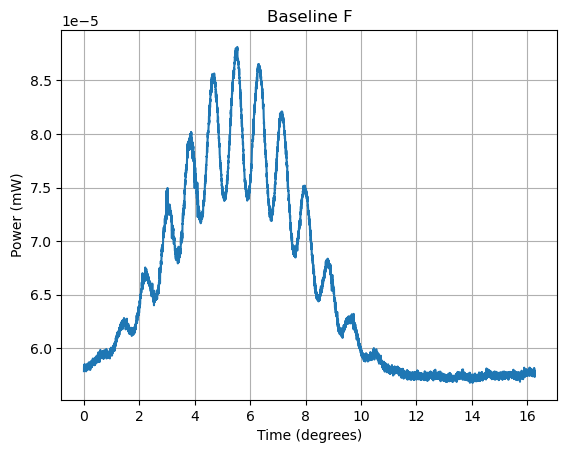

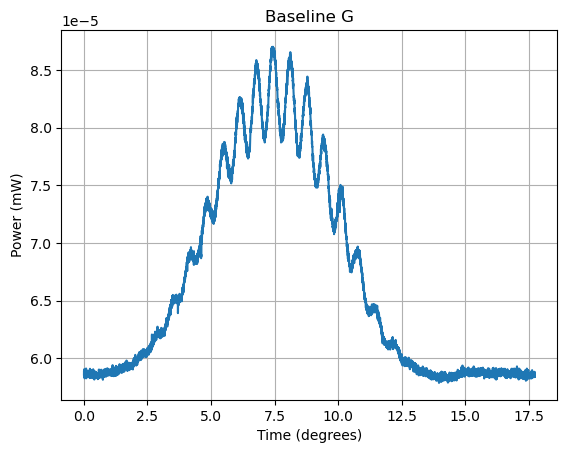

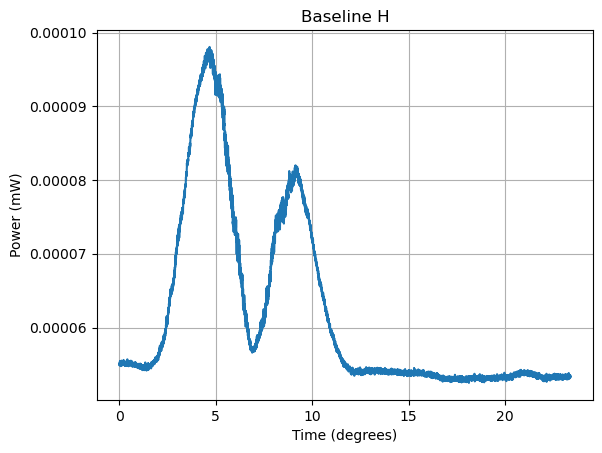

In [5]:
for i in range(0, 8):
    baseline = baselines[i]
    time = times[i]
    power = powers[i]
    plt.figure()
    plt.plot(time, power)
    plt.title(f"Baseline {baseline}")
    plt.xlabel(f"Time (degrees)")
    plt.ylabel(r"Power (mW)")
    plt.grid()
    plt.show()

In [6]:
#flag bad data 
#find pmin and pmax - argrel from scipy signal
#fit gaussians to pmin and pmax
#make linspace same length as data
#P_avg = avg of the two gaussians
#for baseline C: just explain in report and fit w the same gaussians as before

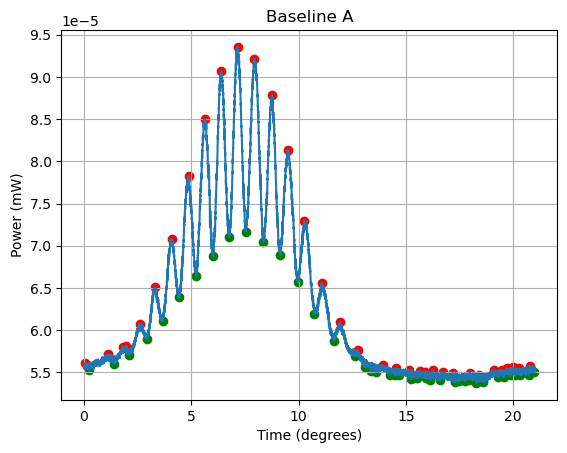

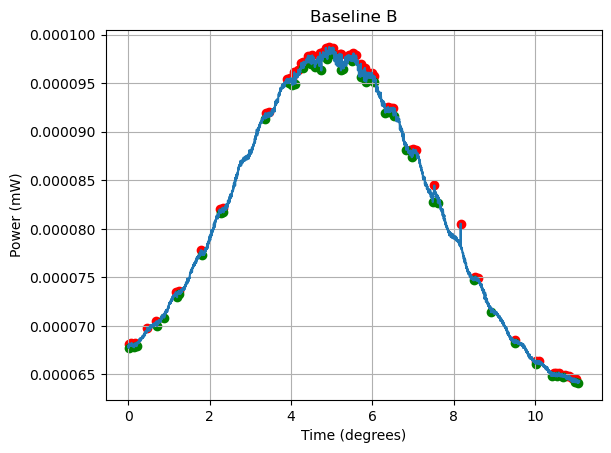

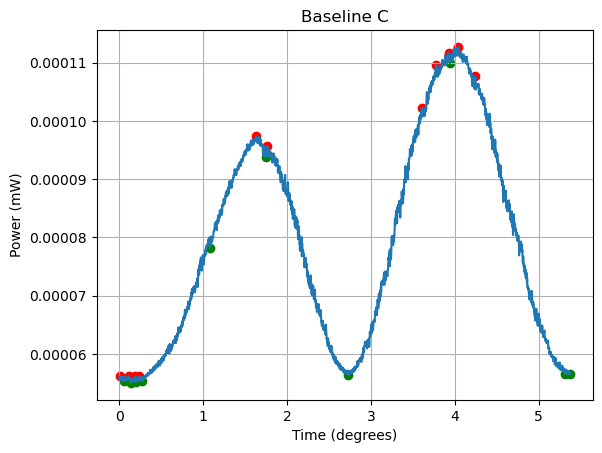

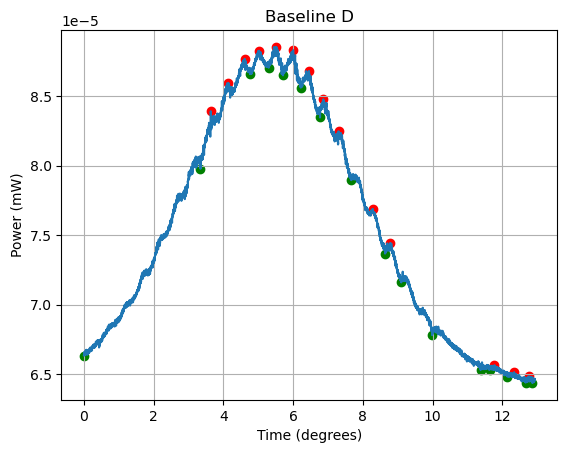

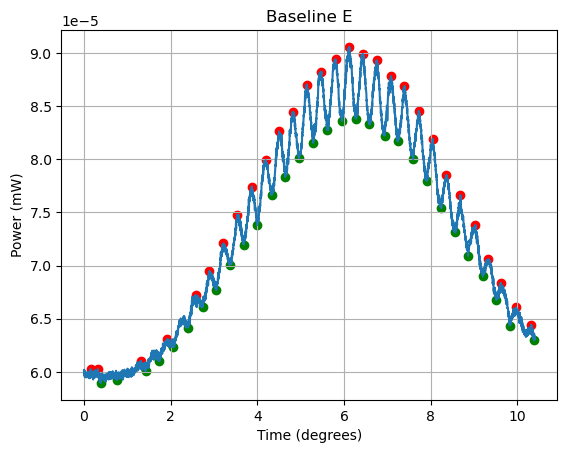

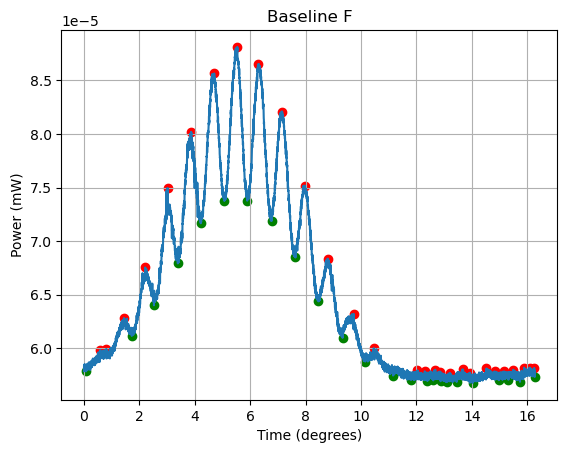

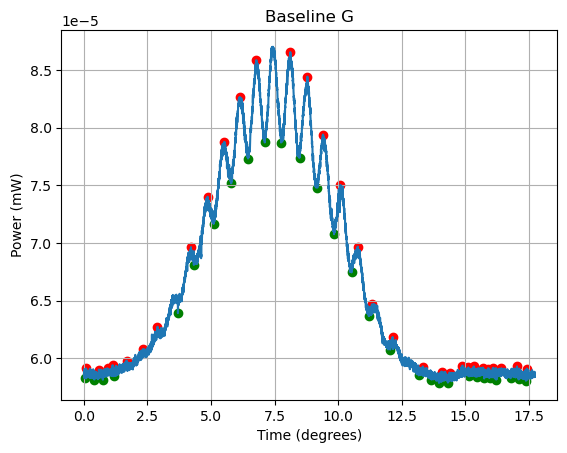

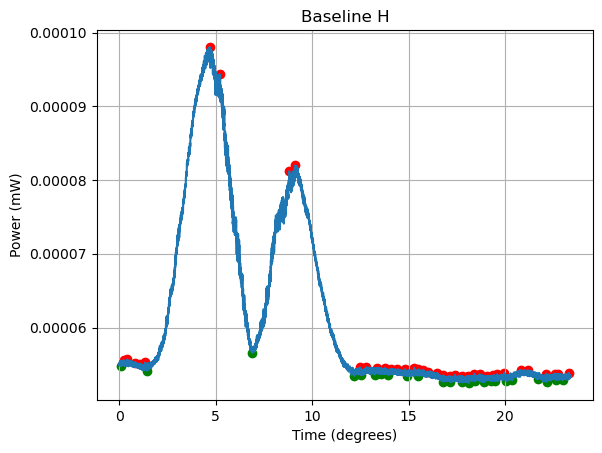

In [7]:
max_vals = [] 
min_vals = [] 
for i in range(0,8): 
    if i == 2: #C 
        maxs = argrelmax(powers[i], axis = 0, order = 20)[0] 
        #20 works also
        max_vals.append(maxs) 
        mins = argrelmin(powers[i], axis = 0, order = 20)[0] 
        min_vals.append(mins) 
    elif i == 1: 
        maxs = argrelmax(powers[i], axis = 0, order = 20)[0] 
        max_vals.append(maxs) 
        mins = argrelmin(powers[i], axis = 0, order = 20)[0] 
        min_vals.append(mins) 
    elif i == 7: 
        maxs = argrelmax(powers[i], axis = 0, order = 80)[0] 
        max_vals.append(maxs) 
        mins = argrelmin(powers[i], axis = 0, order = 100)[0] 
        min_vals.append(mins) 
    else: 
        maxs = argrelmax(powers[i], axis = 0, order = 75)[0] 
        max_vals.append(maxs) 
        mins = argrelmin(powers[i], axis = 0, order = 75)[0] 
        min_vals.append(mins) 
        
for i in range(0,8): 
    max_one = max_vals[i] 
    min_one = min_vals[i] 
    time_one = times[i] 
    power_one = powers[i] 
    baseline = baselines[i] 
    plt.figure() 
    plt.scatter(time_one[max_one], power_one[max_one], color='red') 
    plt.plot(time_one, power_one) 
    plt.scatter(time_one[min_one], power_one[min_one], color='green') 
    plt.title(f"Baseline {baseline}") 
    plt.xlabel(f"Time (degrees)") 
    plt.ylabel(r"Power (mW)") 
    plt.grid() 
    plt.show() 
    #max_A = argrelmax(power_A, axis = 0, order = 75)[0]
    #min_A = argrelmin(power_A, axis = 0, order = 75)[0]

argrelmax/min gives you the index, so we refer to those indices

In [8]:
max_A = max_vals[0]
max_B = max_vals[1]
max_C = max_vals[2]
max_D = max_vals[3]
max_E = max_vals[4]
max_F = max_vals[5]
max_G = max_vals[6]
max_H = max_vals[7]
print(len(max_C))

min_A = min_vals[0]
min_B = min_vals[1]
min_C1 = min_vals[2]
min_C = np.array([61, 89, 122, 1260, 2454, 2481])
print(min_C1)
min_D = min_vals[3]
min_E = min_vals[4]
min_F = min_vals[5]
min_G = min_vals[6]
min_H1 = min_vals[7]
min_H = min_H1[:-1]

max_C = np.append(max_C, min_C[-2:])
print(len(max_C))
#remove: 26, 498, 804, 1819

11
[  26   61   89  122  498  804 1260 1819 2454 2481]
13


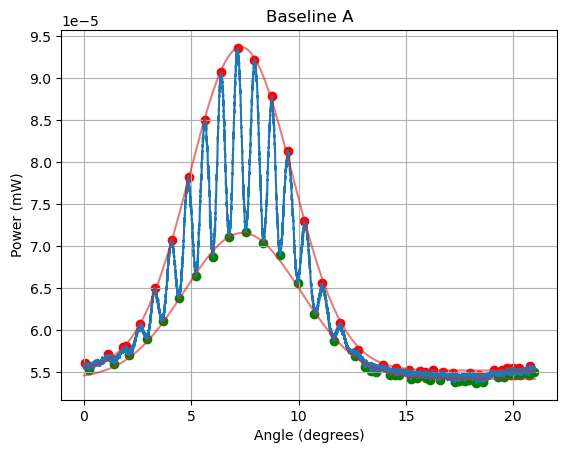

In [9]:
def gaussian(x, A, mu, sigma, C):
    return A * np.exp(-0.5*((x-mu)/sigma)**2) + C

#p0 = [A0, mu0, sigma0, C0]
p0_A = [1e-5, 5, 5, np.median(power_A)]
p0_B = [1e-5, 5, 5, np.median(power_B)]
p0_C = [1e-5, 5, 5, np.median(power_C)]
p0_D = [1e-5, 5, 5, np.median(power_D)]
p0_E = [1e-5, 5, 5, np.median(power_E)]
p0_F = [1e-5, 5, 5, np.median(power_F)]
p0_G = [1e-5, 5, 5, np.median(power_G)]
p0_H = [1e-5, 5, 5, np.median(power_H)]

p0_list = [(p0_A), (p0_B), (p0_C), (p0_D), (p0_E), (p0_F), (p0_G), (p0_H)]

## Fitting the data ##
x_smooth_A = np.linspace(min(time_A), max(time_A), len(time_A)) #should be len(time_A) for the next part

popt_gauss_max_A, pcov_gauss_max_A = curve_fit(gaussian, time_A[max_A], power_A[max_A], p0=p0_list[0])
p_err_max_A = np.sqrt(np.diag(popt_gauss_max_A))
A_fit_max_A, mu_fit_max_A, sigma_fit_max_A, C_fit_max_A = popt_gauss_max_A
A_err_max_A, mu_err_max_A, sigma_err_max_A, C_err_max_A = p_err_max_A

popt_gauss_min_A, pcov_gauss_min_A = curve_fit(gaussian, time_A[min_A], power_A[min_A], p0=p0_list[0])
p_err_min_A = np.sqrt(np.diag(popt_gauss_min_A))
A_fit_min_A, mu_fit_min_A, sigma_fit_min_A, C_fit_min_A = popt_gauss_min_A
A_err_min_A, mu_err_min_A, sigma_err_min_A, C_err_min_A = p_err_min_A

plt.figure()
plt.plot(time_A, power_A)
plt.scatter(time_A[max_A], power_A[max_A], color='red')
plt.scatter(time_A[min_A], power_A[min_A], color='green')
plt.plot(x_smooth_A, gaussian(x_smooth_A, *popt_gauss_max_A), label="Gaussian fit max", c='C3', alpha=0.6)
plt.plot(x_smooth_A, gaussian(x_smooth_A, *popt_gauss_min_A), label="Gaussian fit min", c='C3', alpha=0.6)
plt.title(f"Baseline A")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

In [10]:
"""def vis(popt_gauss_max, popt_gauss_min):
    P_max = popt_gauss_max[0]
    P_min = popt_gauss_min[0]
    P_avg = (P_max+P_min)/2
    good_P_max = P_max - P_avg
    good_P_min = P_min + P_avg
    V = (good_P_max-good_P_min)/(good_P_max+good_P_min)
    return np.fabs(V)
"""
def vis(popt_gauss_max, popt_gauss_min):
    P_max = popt_gauss_max[0]
    P_min = popt_gauss_min[0]
    V = (P_max-P_min)/(P_max+P_min)
    return np.fabs(V)

3.849027610012953e-05
visibility of A =  0.37850104736828133


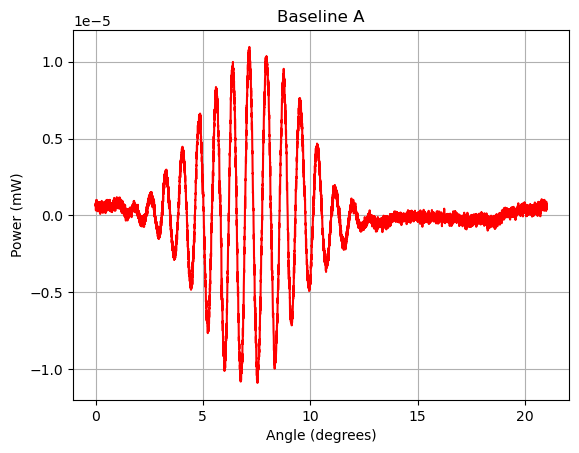

In [11]:
gauss_max_A = gaussian(x_smooth_A, *popt_gauss_max_A)
print(popt_gauss_max_A[0]) #this is the A estimate from fitting
gauss_min_A = gaussian(x_smooth_A, *popt_gauss_min_A)

P_avg_A = (gauss_max_A+gauss_min_A)/2
good_power_A = power_A - P_avg_A

vis_A = vis(popt_gauss_max_A, popt_gauss_min_A)
print("visibility of A = ", vis_A)

plt.figure()
plt.plot(time_A, good_power_A, color='red')
plt.title(f"Baseline A")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

### Baseline B

/tmp/ipykernel_3883660/1230228489.py:4: RuntimeWarning: invalid value encountered in sqrt
  p_err_max_B = np.sqrt(np.diag(popt_gauss_max_B))
/tmp/ipykernel_3883660/1230228489.py:9: RuntimeWarning: invalid value encountered in sqrt
  p_err_min_B = np.sqrt(np.diag(popt_gauss_min_B))


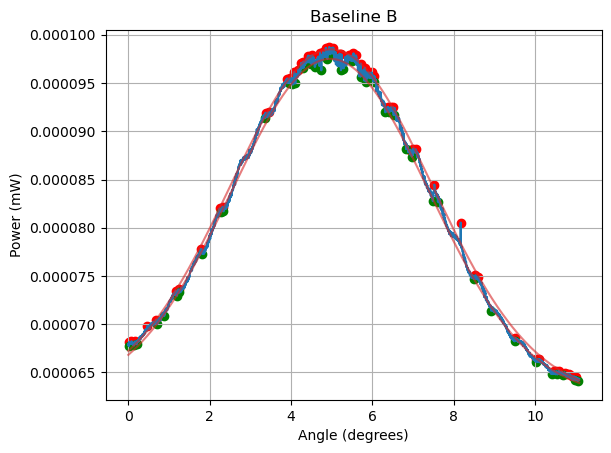

In [12]:
x_smooth_B = np.linspace(min(time_B), max(time_B), len(time_B)) #should be len(time_A) for the next part

popt_gauss_max_B, pcov_gauss_max_B = curve_fit(gaussian, time_B[max_B], power_B[max_B], p0=p0_list[1])
p_err_max_B = np.sqrt(np.diag(popt_gauss_max_B))
A_fit_max_B, mu_fit_max_B, sigma_fit_max_B, C_fit_max_B = popt_gauss_max_B
A_err_max_B, mu_err_max_B, sigma_err_max_B, C_err_max_B = p_err_max_B

popt_gauss_min_B, pcov_gauss_min_B = curve_fit(gaussian, time_B[min_B], power_B[min_B], p0=p0_list[1])
p_err_min_B = np.sqrt(np.diag(popt_gauss_min_B))
A_fit_min_B, mu_fit_min_B, sigma_fit_min_B, C_fit_min_B = popt_gauss_min_B
A_err_min_B, mu_err_min_B, sigma_err_min_B, C_err_min_B = p_err_min_B

plt.figure()
plt.plot(time_B, power_B)
plt.scatter(time_B[max_B], power_B[max_B], color='red')
plt.scatter(time_B[min_B], power_B[min_B], color='green')
plt.plot(x_smooth_B, gaussian(x_smooth_B, *popt_gauss_max_B), label="Gaussian fit max", c='C3', alpha=0.6)
plt.plot(x_smooth_B, gaussian(x_smooth_B, *popt_gauss_min_B), label="Gaussian fit min", c='C3', alpha=0.6)
plt.title(f"Baseline B")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

3.610919000990701e-05
visibility of B =  0.014415461820658405


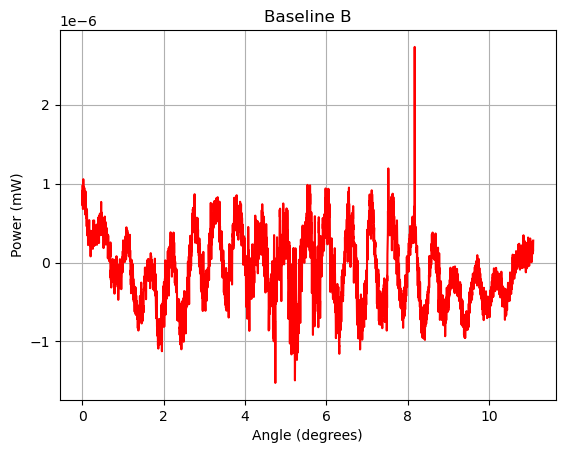

In [13]:
gauss_max_B = gaussian(x_smooth_B, *popt_gauss_max_B)
print(popt_gauss_max_B[0]) #this is the A estimate from fitting
gauss_min_B = gaussian(x_smooth_B, *popt_gauss_min_B)

P_avg_B = (gauss_max_B+gauss_min_B)/2
good_power_B = power_B - P_avg_B

vis_B = vis(popt_gauss_max_B, popt_gauss_min_B)
print("visibility of B = ", vis_B)

plt.figure()
plt.plot(time_B, good_power_B, color='red')
plt.title(f"Baseline B")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

### Baseline C

/tmp/ipykernel_3883660/2434459216.py:9: RuntimeWarning: invalid value encountered in sqrt
  p_err_min_C = np.sqrt(np.diag(popt_gauss_min_C))


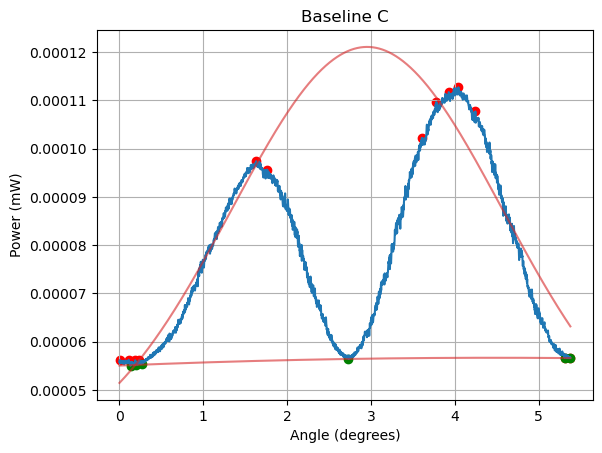

In [14]:
x_smooth_C = np.linspace(min(time_C), max(time_C), len(time_C)) #should be len(time_A) for the next part

popt_gauss_max_C, pcov_gauss_max_C = curve_fit(gaussian, time_C[max_C], power_C[max_C], p0=p0_list[2])
p_err_max_C = np.sqrt(np.diag(popt_gauss_max_C))
A_fit_max_C, mu_fit_max_C, sigma_fit_max_C, C_fit_max_C = popt_gauss_max_C
A_err_max_C, mu_err_max_C, sigma_err_max_C, C_err_max_C = p_err_max_C

popt_gauss_min_C, pcov_gauss_min_C = curve_fit(gaussian, time_C[min_C], power_C[min_C], p0=p0_list[2])
p_err_min_C = np.sqrt(np.diag(popt_gauss_min_C))
A_fit_min_C, mu_fit_min_C, sigma_fit_min_C, C_fit_min_C = popt_gauss_min_C
A_err_min_C, mu_err_min_C, sigma_err_min_C, C_err_min_C = p_err_min_C

plt.figure()
plt.plot(time_C, power_C)
plt.scatter(time_C[max_C], power_C[max_C], color='red')
plt.scatter(time_C[min_C], power_C[min_C], color='green')
plt.plot(x_smooth_C, gaussian(x_smooth_C, *popt_gauss_max_C), label="Gaussian fit max", c='C3', alpha=0.6)
plt.plot(x_smooth_C, gaussian(x_smooth_C, *popt_gauss_min_C), label="Gaussian fit min", c='C3', alpha=0.6)
plt.title(f"Baseline C")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

8.584058763547995e-05
visibility of C =  0.9166431280135522


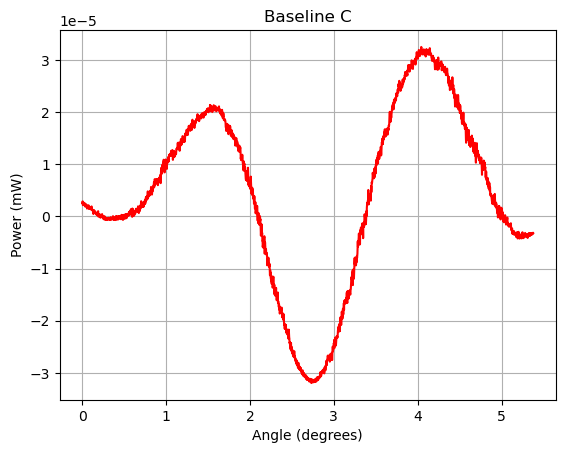

In [15]:
gauss_max_C = gaussian(x_smooth_C, *popt_gauss_max_C)
print(popt_gauss_max_C[0]) #this is the A estimate from fitting
gauss_min_C = gaussian(x_smooth_C, *popt_gauss_min_C)

vis_C = vis(popt_gauss_max_C, popt_gauss_min_C)
print("visibility of C = ", vis_C)

P_avg_C = (gauss_max_C+gauss_min_C)/2
good_power_C = power_C - P_avg_C

plt.figure()
plt.plot(time_C, good_power_C, color='red')
plt.title(f"Baseline C")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

### Baseline D

/tmp/ipykernel_3883660/4006923911.py:9: RuntimeWarning: invalid value encountered in sqrt
  p_err_min_D = np.sqrt(np.diag(popt_gauss_min_D))


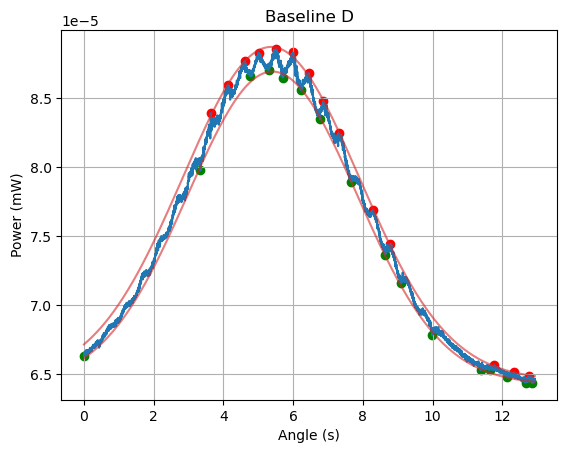

In [16]:
x_smooth_D = np.linspace(min(time_D), max(time_D), len(time_D)) #should be len(time_A) for the next part

popt_gauss_max_D, pcov_gauss_max_D = curve_fit(gaussian, time_D[max_D], power_D[max_D], p0=p0_list[3])
p_err_max_D = np.sqrt(np.diag(popt_gauss_max_D))
A_fit_max_D, mu_fit_max_D, sigma_fit_max_D, C_fit_max_D = popt_gauss_max_D
A_err_max_D, mu_err_max_D, sigma_err_max_D, C_err_max_D = p_err_max_D

popt_gauss_min_D, pcov_gauss_min_D = curve_fit(gaussian, time_D[min_D], power_D[min_D], p0=p0_list[3])
p_err_min_D = np.sqrt(np.diag(popt_gauss_min_D))
A_fit_min_D, mu_fit_min_D, sigma_fit_min_D, C_fit_min_D = popt_gauss_min_D
A_err_min_D, mu_err_min_D, sigma_err_min_D, C_err_min_D = p_err_min_D

plt.figure()
plt.plot(time_D, power_D)
plt.scatter(time_D[max_D], power_D[max_D], color='red')
plt.scatter(time_D[min_D], power_D[min_D], color='green')
plt.plot(x_smooth_D, gaussian(x_smooth_D, *popt_gauss_max_D), label="Gaussian fit max", c='C3', alpha=0.6)
plt.plot(x_smooth_D, gaussian(x_smooth_D, *popt_gauss_min_D), label="Gaussian fit min", c='C3', alpha=0.6)
plt.title(f"Baseline D")
plt.xlabel(f"Angle (s)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

2.4127129883580597e-05
visibility of D =  0.03164368872452274


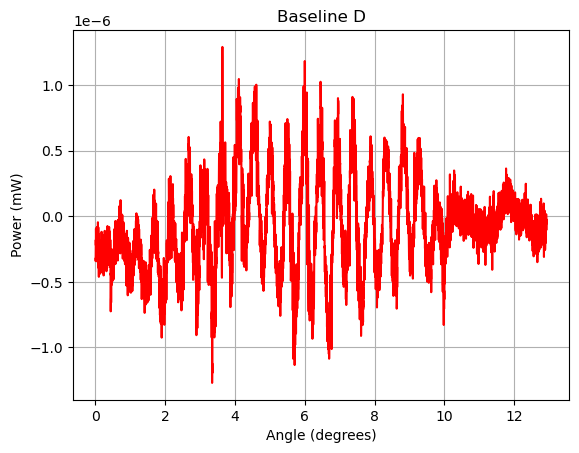

In [17]:
gauss_max_D = gaussian(x_smooth_D, *popt_gauss_max_D)
print(popt_gauss_max_D[0]) #this is the A estimate from fitting
gauss_min_D = gaussian(x_smooth_D, *popt_gauss_min_D)

vis_D = vis(popt_gauss_max_D, popt_gauss_min_D)
print("visibility of D = ", vis_D)

P_avg_D = (gauss_max_D+gauss_min_D)/2
good_power_D = power_D - P_avg_D

plt.figure()
plt.plot(time_D, good_power_D, color='red')
plt.title(f"Baseline D")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

### Baseline E

/tmp/ipykernel_3883660/2709718337.py:4: RuntimeWarning: invalid value encountered in sqrt
  p_err_max_E = np.sqrt(np.diag(popt_gauss_max_E))
/tmp/ipykernel_3883660/2709718337.py:9: RuntimeWarning: invalid value encountered in sqrt
  p_err_min_E = np.sqrt(np.diag(popt_gauss_min_D))


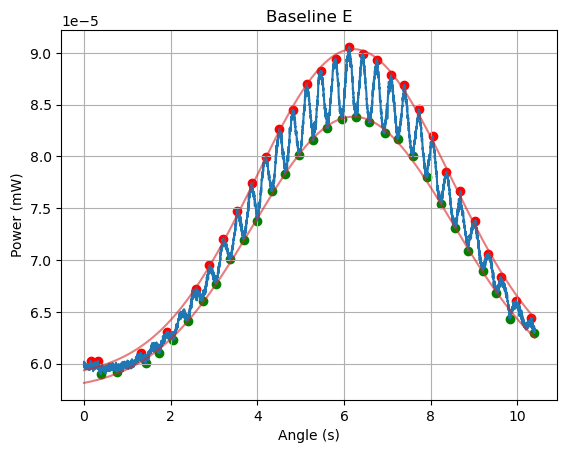

In [18]:
x_smooth_E = np.linspace(min(time_E), max(time_E), len(time_E)) #should be len(time_A) for the next part

popt_gauss_max_E, pcov_gauss_max_E = curve_fit(gaussian, time_E[max_E], power_E[max_E], p0=p0_list[4])
p_err_max_E = np.sqrt(np.diag(popt_gauss_max_E))
A_fit_max_E, mu_fit_max_E, sigma_fit_max_E, C_fit_max_E = popt_gauss_max_E
A_err_max_E, mu_err_max_E, sigma_err_max_E, C_err_max_E = p_err_max_E

popt_gauss_min_E, pcov_gauss_min_E = curve_fit(gaussian, time_E[min_E], power_E[min_E], p0=p0_list[4])
p_err_min_E = np.sqrt(np.diag(popt_gauss_min_D))
A_fit_min_E, mu_fit_min_E, sigma_fit_min_E, C_fit_min_E = popt_gauss_min_E
A_err_min_E, mu_err_min_E, sigma_err_min_E, C_err_min_E = p_err_min_E

plt.figure()
plt.plot(time_E, power_E)
plt.scatter(time_E[max_E], power_E[max_E], color='red')
plt.scatter(time_E[min_E], power_E[min_E], color='green')
plt.plot(x_smooth_E, gaussian(x_smooth_E, *popt_gauss_max_E), label="Gaussian fit max", c='C3', alpha=0.6)
plt.plot(x_smooth_E, gaussian(x_smooth_E, *popt_gauss_min_E), label="Gaussian fit min", c='C3', alpha=0.6)
plt.title(f"Baseline E")
plt.xlabel(f"Angle (s)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

3.171480115936412e-05
visibility of E =  0.09162394965608937


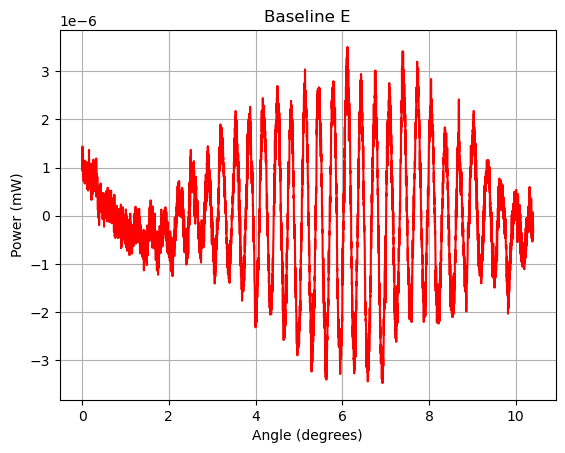

In [19]:
gauss_max_E = gaussian(x_smooth_E, *popt_gauss_max_E)
print(popt_gauss_max_E[0]) #this is the A estimate from fitting
gauss_min_E = gaussian(x_smooth_E, *popt_gauss_min_E)

vis_E = vis(popt_gauss_max_E, popt_gauss_min_E)
print("visibility of E = ", vis_E)

P_avg_E = (gauss_max_E+gauss_min_E)/2
good_power_E = power_E - P_avg_E

plt.figure()
plt.plot(time_E, good_power_E, color='red')
plt.title(f"Baseline E")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

### Baseline F

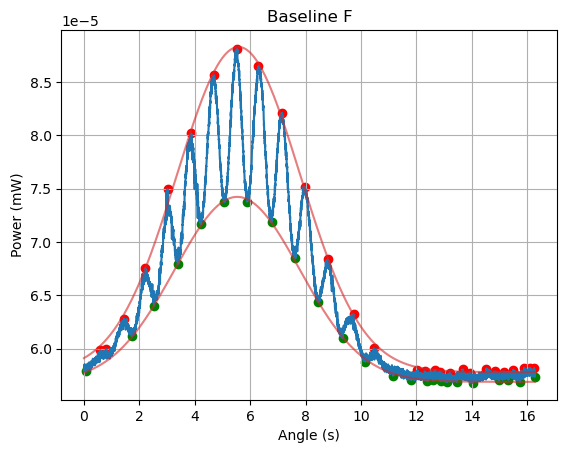

In [20]:
x_smooth_F = np.linspace(min(time_F), max(time_F), len(time_F)) #should be len(time_A) for the next part

popt_gauss_max_F, pcov_gauss_max_F = curve_fit(gaussian, time_F[max_F], power_F[max_F], p0=p0_list[5])
p_err_max_F = np.sqrt(np.diag(popt_gauss_max_F))
A_fit_max_F, mu_fit_max_F, sigma_fit_max_F, C_fit_max_F = popt_gauss_max_F
A_err_max_F, mu_err_max_F, sigma_err_max_F, C_err_max_F = p_err_max_F

popt_gauss_min_F, pcov_gauss_min_F = curve_fit(gaussian, time_F[min_F], power_F[min_F], p0=p0_list[5])
p_err_min_F = np.sqrt(np.diag(popt_gauss_min_F))
A_fit_min_F, mu_fit_min_F, sigma_fit_min_F, C_fit_min_F = popt_gauss_min_F
A_err_min_F, mu_err_min_F, sigma_err_min_F, C_err_min_F = p_err_min_F

plt.figure()
plt.plot(time_F, power_F)
plt.scatter(time_F[max_F], power_F[max_F], color='red')
plt.scatter(time_F[min_F], power_F[min_F], color='green')
plt.plot(x_smooth_F, gaussian(x_smooth_F, *popt_gauss_max_F), label="Gaussian fit max", c='C3', alpha=0.6)
plt.plot(x_smooth_F, gaussian(x_smooth_F, *popt_gauss_min_F), label="Gaussian fit min", c='C3', alpha=0.6)
plt.title(f"Baseline F")
plt.xlabel(f"Angle (s)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

3.052509687520598e-05
visibility of F =  0.2748548048922018


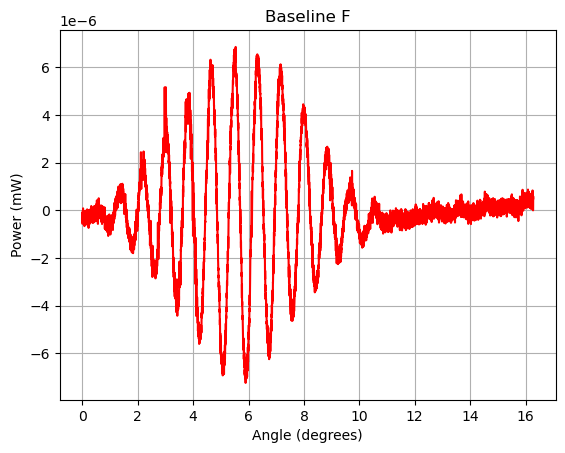

In [21]:
gauss_max_F = gaussian(x_smooth_F, *popt_gauss_max_F)
print(popt_gauss_max_F[0]) #this is the A estimate from fitting
gauss_min_F = gaussian(x_smooth_F, *popt_gauss_min_F)

vis_F = vis(popt_gauss_max_F, popt_gauss_min_F)
print("visibility of F = ", vis_F)

P_avg_F = (gauss_max_F+gauss_min_F)/2
good_power_F = power_F - P_avg_F

plt.figure()
plt.plot(time_F, good_power_F, color='red')
plt.title(f"Baseline F")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

### Baseline G

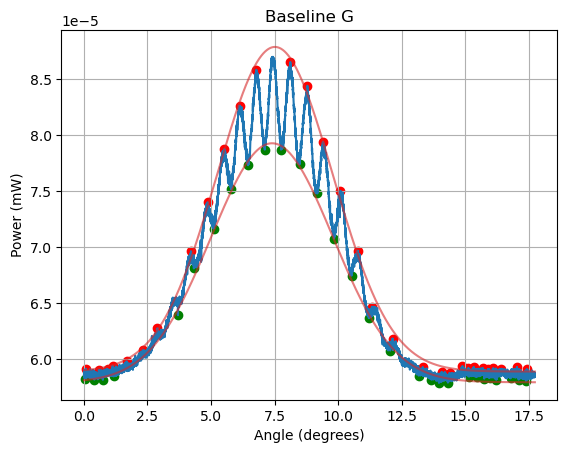

In [22]:
x_smooth_G = np.linspace(min(time_G), max(time_G), len(time_G)) #should be len(time_A) for the next part

popt_gauss_max_G, pcov_gauss_max_G = curve_fit(gaussian, time_G[max_G], power_G[max_G], p0=p0_list[5])
p_err_max_G = np.sqrt(np.diag(popt_gauss_max_G))
A_fit_max_G, mu_fit_max_G, sigma_fit_max_G, C_fit_max_G = popt_gauss_max_G
A_err_max_G, mu_err_max_G, sigma_err_max_G, C_err_max_G = p_err_max_G

popt_gauss_min_G, pcov_gauss_min_G = curve_fit(gaussian, time_G[min_G], power_G[min_G], p0=p0_list[5])
p_err_min_G = np.sqrt(np.diag(popt_gauss_min_G))
A_fit_min_G, mu_fit_min_G, sigma_fit_min_G, C_fit_min_G = popt_gauss_min_G
A_err_min_G, mu_err_min_G, sigma_err_min_G, C_err_min_G = p_err_min_G

plt.figure()
plt.plot(time_G, power_G)
plt.scatter(time_G[max_G], power_G[max_G], color='red')
plt.scatter(time_G[min_G], power_G[min_G], color='green')
plt.plot(x_smooth_G, gaussian(x_smooth_G, *popt_gauss_max_G), label="Gaussian fit max", c='C3', alpha=0.6)
plt.plot(x_smooth_G, gaussian(x_smooth_G, *popt_gauss_min_G), label="Gaussian fit min", c='C3', alpha=0.6)
plt.title(f"Baseline G")
plt.xlabel(f"Angle (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

2.8995771238423412e-05
visibility of G =  0.15190718094511454


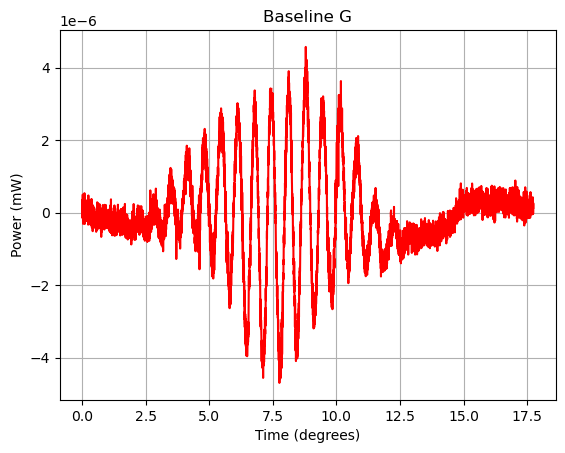

In [23]:
gauss_max_G = gaussian(x_smooth_G, *popt_gauss_max_G)
print(popt_gauss_max_G[0]) #this is the A estimate from fitting
gauss_min_G = gaussian(x_smooth_G, *popt_gauss_min_G)

vis_G = vis(popt_gauss_max_G, popt_gauss_min_G)
print("visibility of G = ", vis_G)

P_avg_G = (gauss_max_G+gauss_min_G)/2
good_power_G = power_G - P_avg_G

plt.figure()
plt.plot(time_G, good_power_G, color='red')
plt.title(f"Baseline G")
plt.xlabel(f"Time (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

### Baseline H

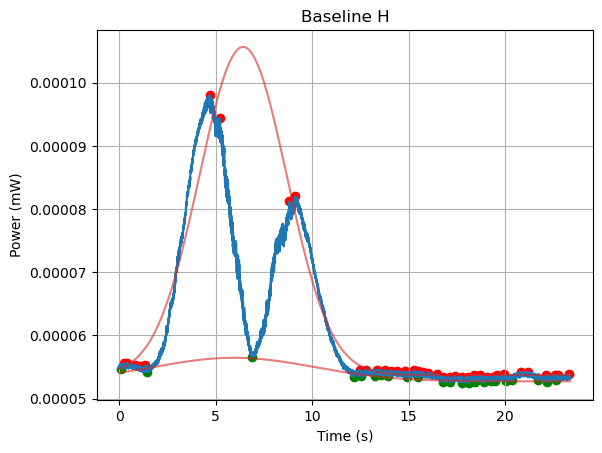

In [24]:
x_smooth_H = np.linspace(min(time_H), max(time_H), len(time_H)) #should be len(time_A) for the next part

popt_gauss_max_H, pcov_gauss_max_H = curve_fit(gaussian, time_H[max_H], power_H[max_H], p0=p0_list[5])
p_err_max_H = np.sqrt(np.diag(popt_gauss_max_G))
A_fit_max_H, mu_fit_max_H, sigma_fit_max_H, C_fit_max_H = popt_gauss_max_H
A_err_max_H, mu_err_max_H, sigma_err_max_H, C_err_max_H = p_err_max_H

popt_gauss_min_H, pcov_gauss_min_H = curve_fit(gaussian, time_H[min_H], power_H[min_H], p0=p0_list[5])
p_err_min_H = np.sqrt(np.diag(popt_gauss_min_G))
A_fit_min_H, mu_fit_min_H, sigma_fit_min_H, C_fit_min_H = popt_gauss_min_H
A_err_min_H, mu_err_min_H, sigma_err_min_H, C_err_min_H = p_err_min_H

plt.figure()
plt.plot(time_H, power_H)
plt.scatter(time_H[max_H], power_H[max_H], color='red')
plt.scatter(time_H[min_H], power_H[min_H], color='green')
plt.plot(x_smooth_H, gaussian(x_smooth_H, *popt_gauss_max_H), label="Gaussian fit max", c='C3', alpha=0.6)
plt.plot(x_smooth_H, gaussian(x_smooth_H, *popt_gauss_min_H), label="Gaussian fit min", c='C3', alpha=0.6)
plt.title(f"Baseline H")
plt.xlabel(f"Time (s)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

5.190412959760907e-05
visibility of H =  0.8658581448189866


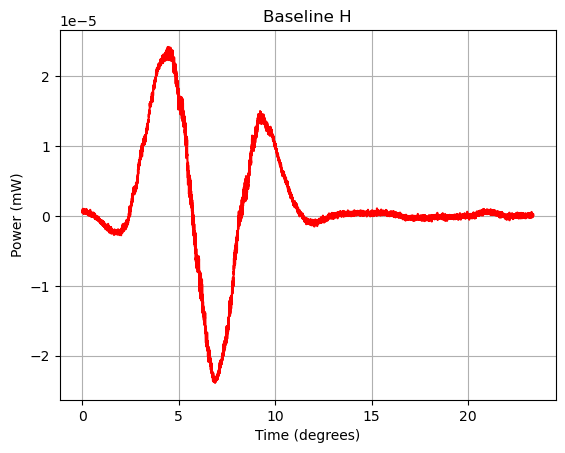

In [25]:
gauss_max_H = gaussian(x_smooth_H, *popt_gauss_max_H)
print(popt_gauss_max_H[0]) #this is the A estimate from fitting
gauss_min_H = gaussian(x_smooth_H, *popt_gauss_min_H)

vis_H = vis(popt_gauss_max_H, popt_gauss_min_H)
print("visibility of H = ", vis_H)

P_avg_H = (gauss_max_H+gauss_min_H)/2
good_power_H = power_H - P_avg_H

plt.figure()
plt.plot(time_H, good_power_H, color='red')
plt.title(f"Baseline H")
plt.xlabel(f"Time (degrees)")
plt.ylabel(r"Power (mW)")
plt.grid()
plt.show()

W_fringe is the width of the fringe

sigma_P_min is the uncertainty in A_min (amplitude of minimum gaussian)

def std_V(pcov_p, pcov_d, Pmin, Pmax):
    sigma_Ap = np.sqrt(pcov_p[0,0])
    sigma_Cp = np.sqrt(pcov_p[3,3])
    sigma_Ad = np.sqrt(pcov_d[0,0])
    sigma_Hd = np.sqrt(pcov_d[3,3])

    sigma_Pmax = np.sqrt(sigma_Hp**2 + sigma_Ap**2)
    sigma_Pmin = np.sqrt(sigma_Hd**2 + sigma_Ad**2)
    
    sigma_V = 2*(np.sqrt((Pmin * sigma_Pmax)**2+(Pmax * sigma_Pmin)**2))/((Pmin + Pmax)**2)
    
    
    return sigma_V

In [26]:
def std_V(pcov_1, pcov_2, Pmin, Pmax):
    sigma_A1 = np.sqrt(pcov_1[0,0])
    sigma_A2 = np.sqrt(pcov_2[0,0])
    sigma_Pmax = np.sqrt(sigma_A1**2 )
    sigma_Pmin = np.sqrt(sigma_A2**2)
    sigma_V = 2*(np.sqrt((Pmin * sigma_Pmax)**2+(Pmax * sigma_Pmin)**2))/((Pmin + Pmax)**2)
    return sigma_V

unc_vis_A = std_V(pcov_gauss_min_A, pcov_gauss_max_A, A_fit_min_A, A_fit_max_A)
print("vis A = ", vis_A)
print("unc vis A = ", unc_vis_A)

unc_vis_B = std_V(pcov_gauss_min_B, pcov_gauss_max_B, A_fit_min_B, A_fit_max_B)
print("vis B = ", vis_B)
print("unc vis B = ", unc_vis_B)

unc_vis_C = std_V(pcov_gauss_min_C, pcov_gauss_max_C, A_fit_min_C, A_fit_max_C)
print("vis C = ", vis_C)
print("unc vis C = ", unc_vis_C)

unc_vis_D = std_V(pcov_gauss_min_D, pcov_gauss_max_D, A_fit_min_D, A_fit_max_D)
print("vis D = ", vis_D)
print("unc vis D = ", unc_vis_D)

unc_vis_E = std_V(pcov_gauss_min_E, pcov_gauss_max_E, A_fit_min_E, A_fit_max_E)
print("vis E = ", vis_E)
print("unc vis E = ", unc_vis_E)

unc_vis_F = std_V(pcov_gauss_min_F, pcov_gauss_max_F, A_fit_min_F, A_fit_max_F)
print("vis F = ", vis_F)
print("unc vis F = ", unc_vis_F)

unc_vis_G = std_V(pcov_gauss_min_G, pcov_gauss_max_G, A_fit_min_G, A_fit_max_G)
print("vis G = ", vis_G)
print("unc vis G = ", unc_vis_G)

unc_vis_H = std_V(pcov_gauss_min_H, pcov_gauss_max_H, A_fit_min_H, A_fit_max_H)
print("vis H = ", vis_H)
print("unc vis H = ", unc_vis_H)

vis A =  0.37850104736828133
unc vis A =  0.005565950212220534
vis B =  0.014415461820658405
unc vis B =  0.005633506798895543
vis C =  0.9166431280135522
unc vis C =  10696.473856881248
vis D =  0.03164368872452274
unc vis D =  0.004428311199936301
vis E =  0.09162394965608937
unc vis E =  0.007647977577886455
vis F =  0.2748548048922018
unc vis F =  0.007394546561942414
vis G =  0.15190718094511454
unc vis G =  0.007776073188390323
vis H =  0.8658581448189866
unc vis H =  0.06295933918581698


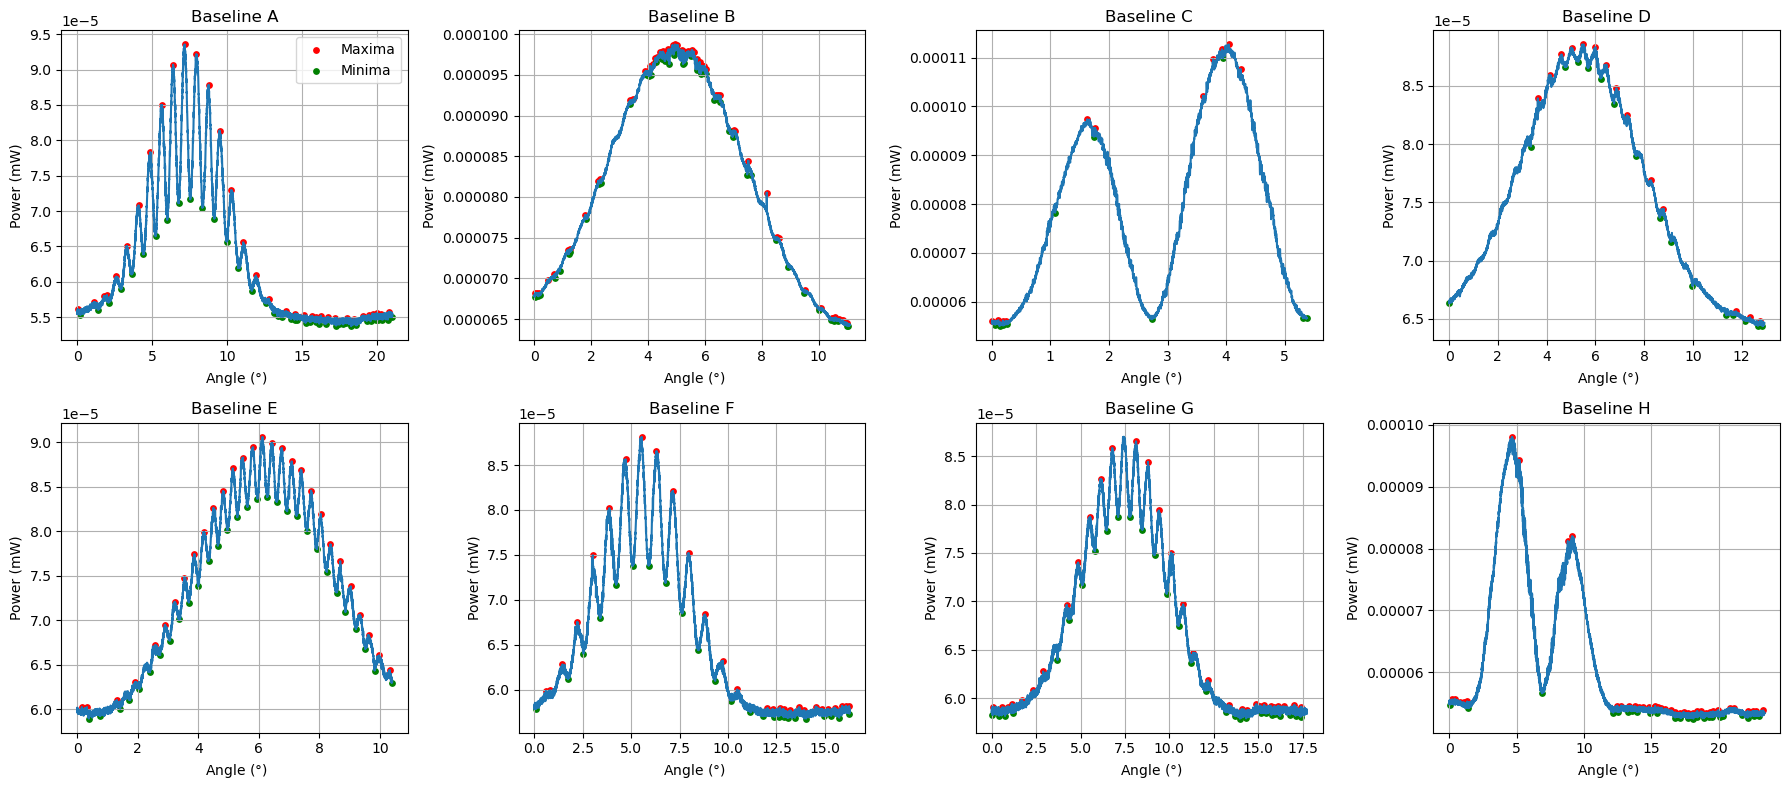

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=False, sharey=False)
axes = axes.flatten()

for i in range(8):
    ax = axes[i]
    time_i = times[i]         
    power_i = powers[i]    
    max_i = max_vals[i]        
    min_i = min_vals[i]    
    baseline_i = baselines[i]

    ax.plot(time_i, power_i)
    ax.scatter(time_i[max_i], power_i[max_i], color='red', s=15, label='Maxima')
    ax.scatter(time_i[min_i], power_i[min_i], color='green', s=15, label='Minima')

    ax.set_title(f"Baseline {baseline_i}")
    ax.set_xlabel(r" Angle ($\degree$)")
    ax.set_ylabel("Power (mW)")
    ax.grid(True)

axes[0].legend(loc="best")

plt.tight_layout()
plt.show()


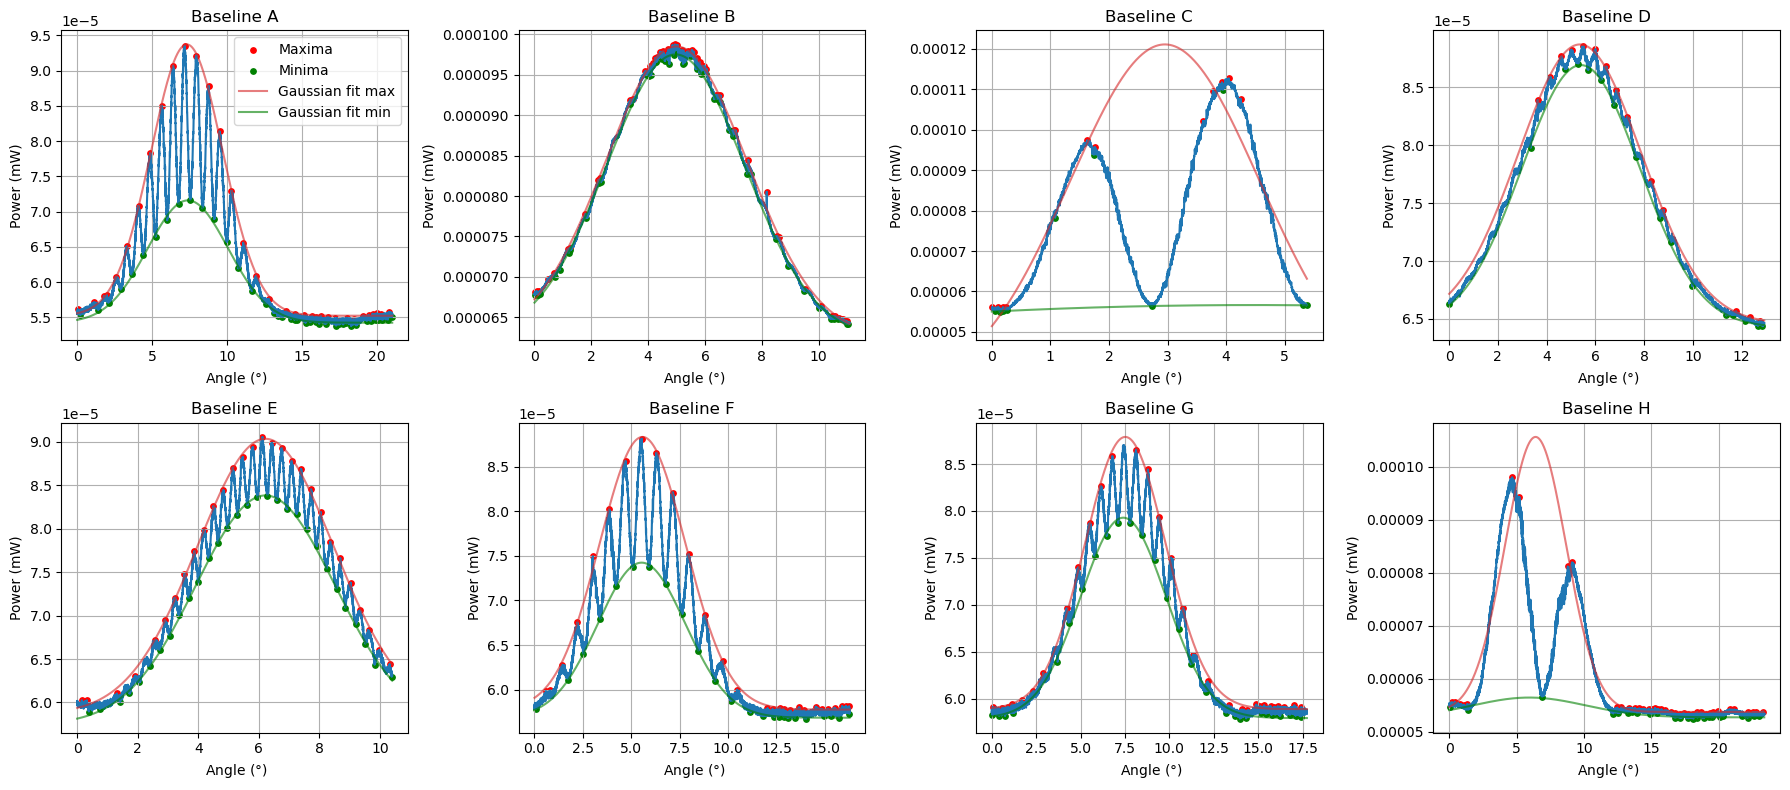

In [28]:
x_smooth_list = [x_smooth_A, x_smooth_B, x_smooth_C, x_smooth_D, x_smooth_E, x_smooth_F, x_smooth_G, x_smooth_H]
gauss_list_max = [(gaussian(x_smooth_A, *popt_gauss_max_A)), (gaussian(x_smooth_B, *popt_gauss_max_B)), (gaussian(x_smooth_C, *popt_gauss_max_C)), (gaussian(x_smooth_D, *popt_gauss_max_D)), (gaussian(x_smooth_E, *popt_gauss_max_E)), (gaussian(x_smooth_F, *popt_gauss_max_F)), (gaussian(x_smooth_G, *popt_gauss_max_G)), (gaussian(x_smooth_H, *popt_gauss_max_H))]
gauss_list_min = [(gaussian(x_smooth_A, *popt_gauss_min_A)), (gaussian(x_smooth_B, *popt_gauss_min_B)), (gaussian(x_smooth_C, *popt_gauss_min_C)), (gaussian(x_smooth_D, *popt_gauss_min_D)), (gaussian(x_smooth_E, *popt_gauss_min_E)), (gaussian(x_smooth_F, *popt_gauss_min_F)), (gaussian(x_smooth_G, *popt_gauss_min_G)), (gaussian(x_smooth_H, *popt_gauss_min_H))]


fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=False, sharey=False)
axes = axes.flatten()

for i in range(8):
    ax = axes[i]
    time_i = times[i]         
    power_i = powers[i]    
    max_i = max_vals[i]        
    min_i = min_vals[i]    
    baseline_i = baselines[i]
    smooth_list_i = x_smooth_list[i]
    gauss_max_i = gauss_list_max[i]
    gauss_min_i = gauss_list_min[i]

    ax.plot(time_i, power_i)
    ax.scatter(time_i[max_i], power_i[max_i], color='red', s=15, label='Maxima')
    ax.scatter(time_i[min_i], power_i[min_i], color='green', s=15, label='Minima')
    ax.plot(smooth_list_i, gauss_max_i, label="Gaussian fit max", c='C3', alpha=0.6)
    ax.plot(smooth_list_i, gauss_min_i, label="Gaussian fit min", color='green', alpha=0.6)
    ax.set_title(f"Baseline {baseline_i}")
    ax.set_xlabel(r" Angle ($\degree$)")
    ax.set_ylabel("Power (mW)")
    ax.grid(True)

axes[0].legend(loc="best")

plt.tight_layout()
plt.show()

## Baseline determination

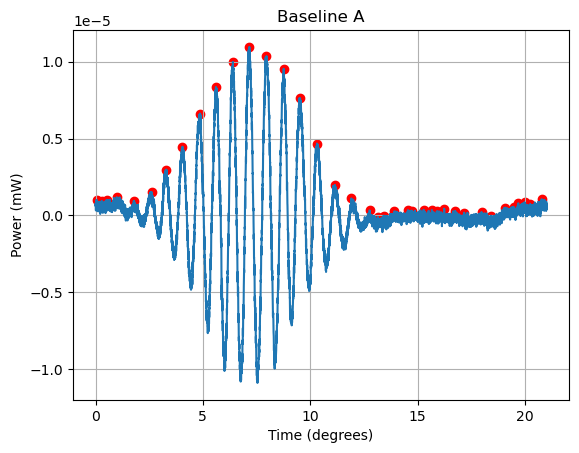

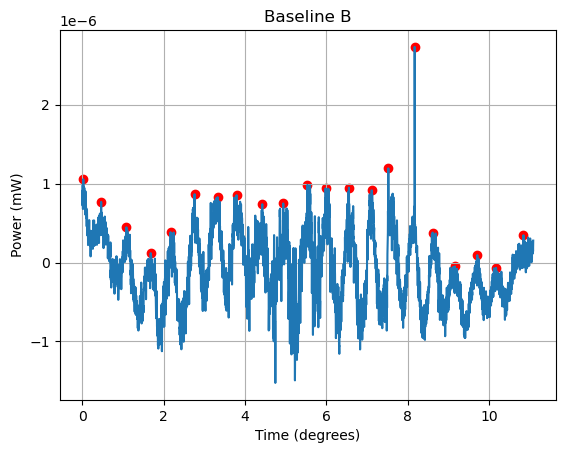

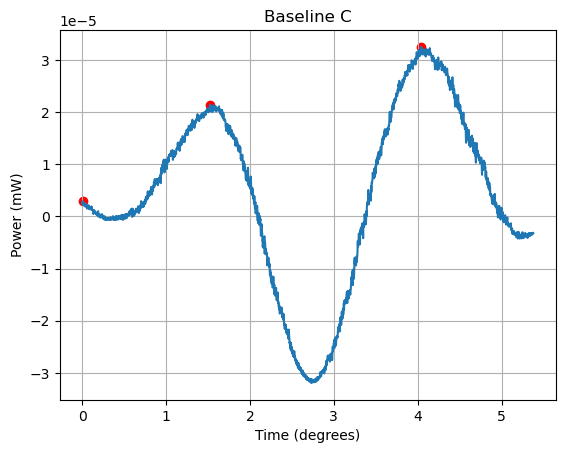

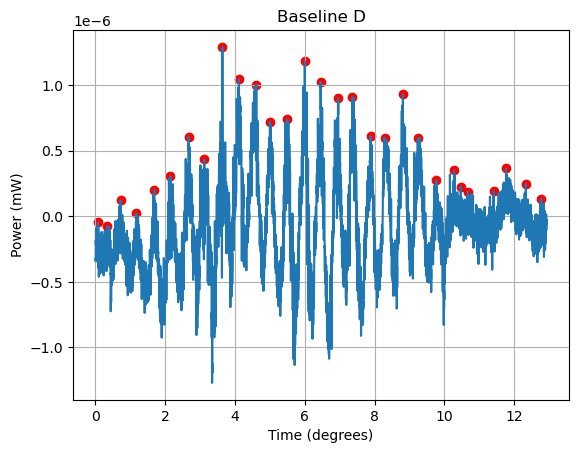

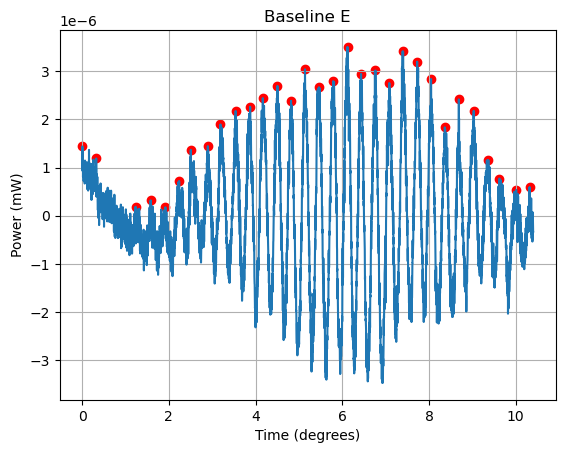

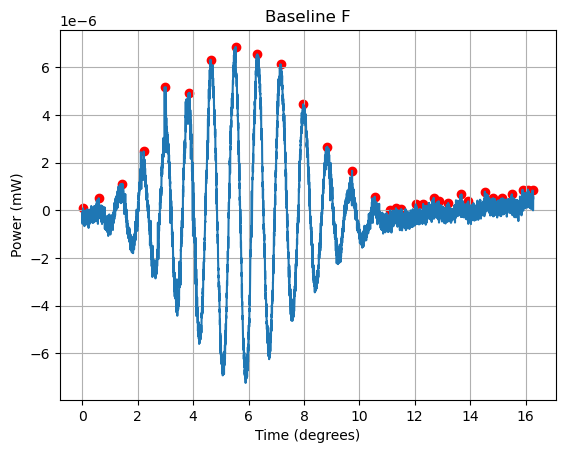

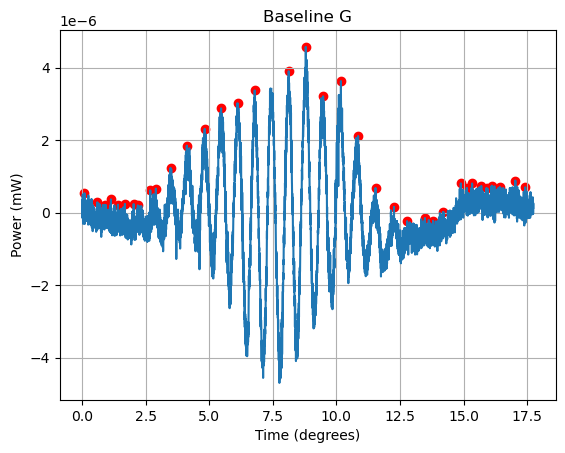

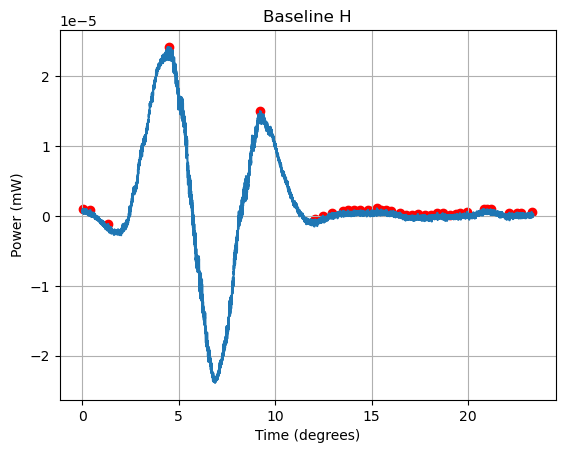

In [29]:
#find peaks again, because W_fringe should be the peak-to-peak width
#so we get the indices, and here do time[i+1] - time[i]

good_powers = [good_power_A, good_power_B, good_power_C, good_power_D, good_power_E, good_power_F, good_power_G, good_power_H]

max_vals_W = []
for i in range(0,8):
    maxs = argrelmax(good_powers[i], axis = 0, order = 75)[0]
    max_vals_W.append(maxs)
    
max_vals_W_A = max_vals_W[0]
max_vals_W_B = max_vals_W[1]
max_vals_W_C = max_vals_W[2]
max_vals_W_D = max_vals_W[3]
max_vals_W_E = max_vals_W[4]
max_vals_W_F = max_vals_W[5]
max_vals_W_G = max_vals_W[6]
max_vals_W_H = max_vals_W[7]

for i in range(0,8):
    max_one1 = max_vals_W[i]
    time_one = times[i]
    power_one1 = good_powers[i]
    baseline = baselines[i]
    plt.figure()
    plt.scatter(time_one[max_one1], power_one1[max_one1], color='red')
    plt.plot(time_one, power_one1)
    plt.title(f"Baseline {baseline}")
    plt.xlabel(f"Time (degrees)")
    plt.ylabel(r"Power (mW)")
    plt.grid()
    plt.show()

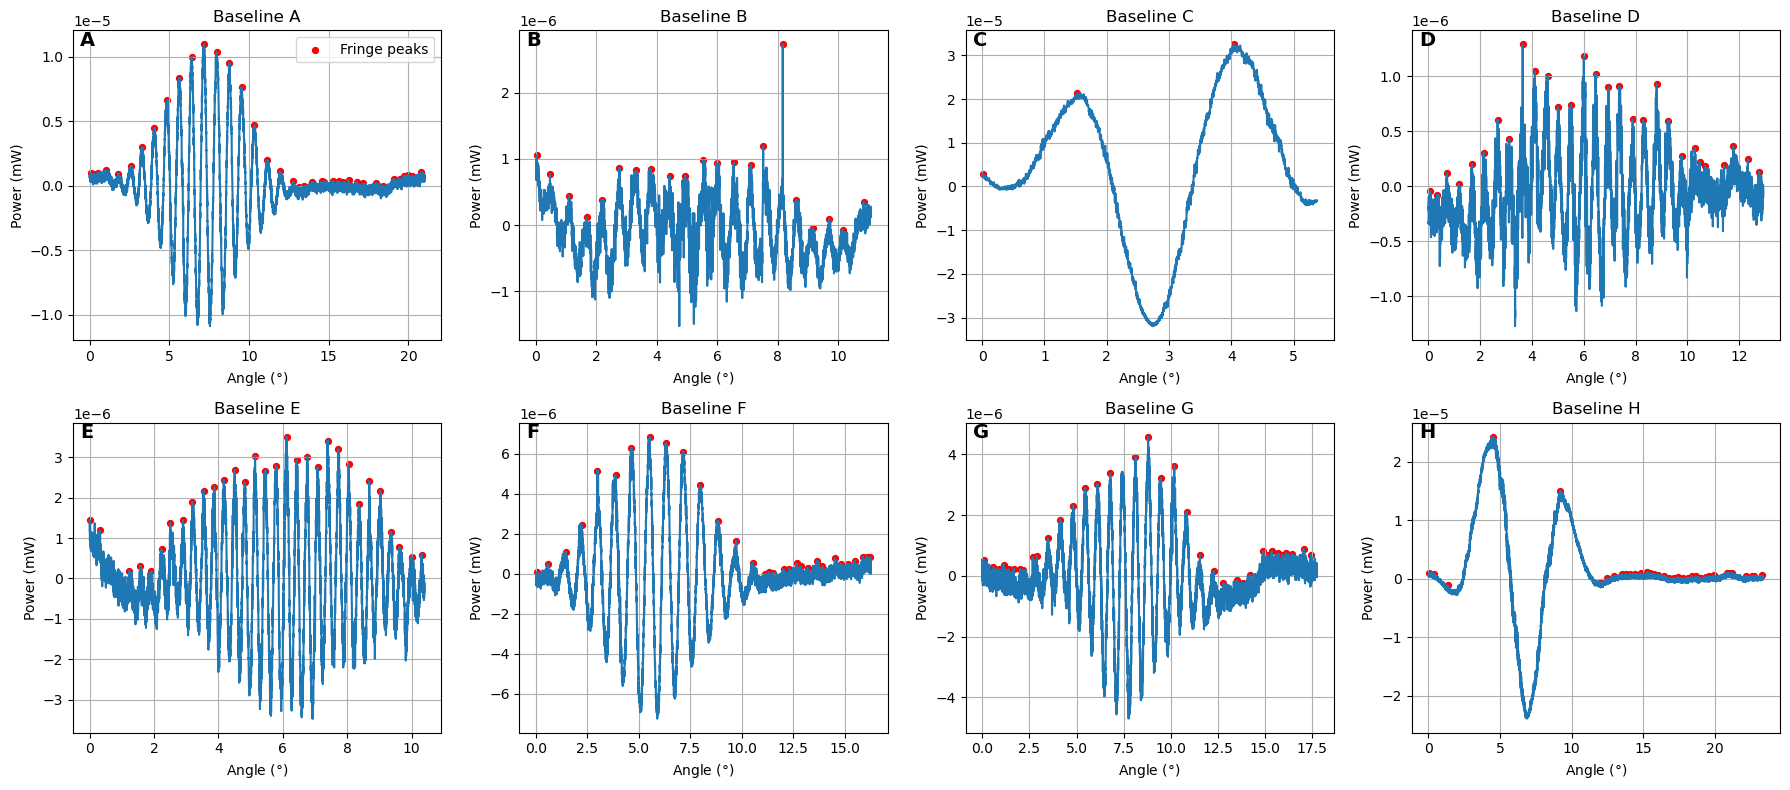

In [30]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=False, sharey=False)
axes = axes.flatten()

for i in range(8):
    ax = axes[i]
    time_i = times[i]           
    power_i = good_powers[i]  
    max_i = max_vals_W[i]      
    baseline_i = baselines[i]   
    ax.plot(time_i, power_i)
    ax.scatter(time_i[max_i], power_i[max_i], color='red', s=18, label='Fringe peaks')

    ax.set_title(f"Baseline {baseline_i}")
    ax.set_xlabel(r"Angle ($\degree$)")
    ax.set_ylabel("Power (mW)")
    ax.grid(True)
    ax.text(0.02, 0.95, chr(ord('A') + i), transform=ax.transAxes, fontsize=14, fontweight='bold')

axes[0].legend(loc="best")

plt.tight_layout()
plt.show()

you have two gaussians, P_max_max = P_max + P_Avg and P_min_min = P_min - P_avg. for the P_max and P_min, you should do V using P_max (so subtract P_Avg) and P_min (so add P_avg)

so first i got the time coords of the max points, then i use slicing after inspecting by eye to see which max points are important. then, make an average from all of this.

In [31]:
W_fringe_list_A = []

max_time_A = time_A[max_vals_W_A] #this gets the time coords of the max points
#print(max_time_A)
for i in range(1, len(max_time_A)):
    period = max_time_A[i] - max_time_A[i-1]
    W_fringe_list_A.append(period)

#print(W_fringe_list_A)
#good_W_fringe_list_A = np.deg2rad(W_fringe_list_A[3:15])
good_W_fringe_list_A = (W_fringe_list_A[3:15])
#print(good_W_fringe_list_A)
avg_W_fringe_A = np.mean(good_W_fringe_list_A)
sigma_W_fringe_A = np.std(good_W_fringe_list_A, ddof=1) / np.sqrt(len(good_W_fringe_list_A))
avg_W_fringe_A = float(avg_W_fringe_A)
print("average W_fringe for baseline A: ", avg_W_fringe_A)

W_fringe_list_B = []

max_time_B = time_B[max_vals_W_B] #this gets the time coords of the max points
#print(max_time_A)
for i in range(1, len(max_time_B)):
    period = max_time_B[i] - max_time_B[i-1]
    W_fringe_list_B.append(period)

#print(W_fringe_list_B)
#good_W_fringe_list_B = np.deg2rad(W_fringe_list_B[:-1])
good_W_fringe_list_B = (W_fringe_list_B[:-1])
#print(good_W_fringe_list_B)
avg_W_fringe_B = np.mean(good_W_fringe_list_B)
avg_W_fringe_B = float(avg_W_fringe_B)
sigma_W_fringe_B = np.std(good_W_fringe_list_B, ddof=1) / np.sqrt(len(good_W_fringe_list_B))
print("average W_fringe for baseline B: ", avg_W_fringe_B)

W_fringe_list_C = []

max_time_C = time_C[max_vals_W_C] #this gets the time coords of the max points
#print(max_time_A)
for i in range(1, len(max_time_C)):
    period = max_time_C[i] - max_time_C[i-1]
    W_fringe_list_C.append(period)

#print(W_fringe_list_C)
#good_W_fringe_list_C = np.deg2rad(W_fringe_list_C[-1])
good_W_fringe_list_C = (W_fringe_list_C[-1])
#print(good_W_fringe_list_C)
avg_W_fringe_C = np.mean(good_W_fringe_list_C)
avg_W_fringe_C = float(avg_W_fringe_C)
sigma_W_fringe_C = np.std(good_W_fringe_list_C, ddof=1) / np.sqrt(1)

print("average W_fringe for baseline C: ", avg_W_fringe_C)

W_fringe_list_D = []

max_time_D = time_D[max_vals_W_D] #this gets the time coords of the max points
#print(max_time_A)
for i in range(1, len(max_time_D)):
    period = max_time_D[i] - max_time_D[i-1]
    W_fringe_list_D.append(period)

#print(W_fringe_list_D)
#good_W_fringe_list_D = (W_fringe_list_D[2:22])
#good_W_fringe_list_D = np.deg2rad(W_fringe_list_D[2:22])
good_W_fringe_list_D = (W_fringe_list_D[2:22])

#print(good_W_fringe_list_D)
avg_W_fringe_D = np.mean(good_W_fringe_list_D)
avg_W_fringe_D = float(avg_W_fringe_D)
sigma_W_fringe_D = np.std(good_W_fringe_list_D, ddof=1) / np.sqrt(len(good_W_fringe_list_D))
print("average W_fringe for baseline D: ", avg_W_fringe_D)

W_fringe_list_E = []

max_time_E = time_E[max_vals_W_E] #this gets the time coords of the max points
#print(max_time_A)
for i in range(1, len(max_time_E)):
    period = max_time_E[i] - max_time_E[i-1]
    W_fringe_list_E.append(period)

#print(W_fringe_list_E)
#good_W_fringe_list_E = np.deg2rad(W_fringe_list_E[2:])
good_W_fringe_list_E = (W_fringe_list_E[2:])

#print(good_W_fringe_list_E)
avg_W_fringe_E = np.mean(good_W_fringe_list_E)
sigma_W_fringe_E = np.std(good_W_fringe_list_E, ddof=1) / np.sqrt(len(good_W_fringe_list_E))
avg_W_fringe_E = float(avg_W_fringe_E)
print("average W_fringe for baseline E: ", avg_W_fringe_E)

W_fringe_list_F = []

max_time_F = time_F[max_vals_W_F] #this gets the time coords of the max points
#print(max_time_A)
for i in range(1, len(max_time_F)):
    period = max_time_F[i] - max_time_F[i-1]
    W_fringe_list_F.append(period)

#print(W_fringe_list_F)
#good_W_fringe_list_F = np.deg2rad(W_fringe_list_F[1:13])
good_W_fringe_list_F = (W_fringe_list_F[1:13])

#print(good_W_fringe_list_F)
avg_W_fringe_F = np.mean(good_W_fringe_list_F)
avg_W_fringe_F = float(avg_W_fringe_F)
sigma_W_fringe_F = np.std(good_W_fringe_list_F, ddof=1) / np.sqrt(len(good_W_fringe_list_F))

print("average W_fringe for baseline F: ", avg_W_fringe_F)

W_fringe_list_G = []

max_time_G = time_G[max_vals_W_G] #this gets the time coords of the max points
#print(max_time_A)
for i in range(1, len(max_time_G)):
    period = max_time_G[i] - max_time_G[i-1]
    W_fringe_list_G.append(period)

#print(W_fringe_list_G)
good_W_fringe_list_G = (W_fringe_list_G[10:15]) + (W_fringe_list_G[16:22])

#print(good_W_fringe_list_G)
#avg_W_fringe_G = np.mean(np.deg2rad(good_W_fringe_list_G))
avg_W_fringe_G = np.mean((good_W_fringe_list_G))
sigma_W_fringe_G = np.std(good_W_fringe_list_G, ddof=1) / np.sqrt(len(good_W_fringe_list_G))

avg_W_fringe_G = float(avg_W_fringe_G)
print("average W_fringe for baseline G: ", avg_W_fringe_G)

W_fringe_list_H = []

max_time_H = time_H[max_vals_W_H] #this gets the time coords of the max points
#print(max_time_A)
for i in range(1, len(max_time_H)):
    period = max_time_H[i] - max_time_H[i-1]
    W_fringe_list_H.append(period)

#print(W_fringe_list_H)
#good_W_fringe_list_H = np.deg2rad(W_fringe_list_H[3])
good_W_fringe_list_H = (W_fringe_list_H[3])

#print(good_W_fringe_list_H)
avg_W_fringe_H = np.mean(good_W_fringe_list_H)
avg_W_fringe_H = float(avg_W_fringe_H)
sigma_W_fringe_H = np.std(good_W_fringe_list_H, ddof=1) / np.sqrt(1)
print("average W_fringe for baseline H: ", avg_W_fringe_H)

average W_fringe for baseline A:  0.7773963222076389
average W_fringe for baseline B:  0.5338828267506447
average W_fringe for baseline C:  2.5172503873708334
average W_fringe for baseline D:  0.4780726027237499
average W_fringe for baseline E:  0.32475473169374997
average W_fringe for baseline F:  0.829794817378125
average W_fringe for baseline G:  0.6776012692939395
average W_fringe for baseline H:  4.729316891208334


/Software/users/modules/9/software/anaconda3/2024.02/lib/python3.11/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Software/users/modules/9/software/anaconda3/2024.02/lib/python3.11/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [32]:
unc_W_fringe = [sigma_W_fringe_A, sigma_W_fringe_B, sigma_W_fringe_C, sigma_W_fringe_D, sigma_W_fringe_E, sigma_W_fringe_F, sigma_W_fringe_G, sigma_W_fringe_H]
print(unc_W_fringe)

[0.010877260888214096, 0.016933522953424044, nan, 0.009532477092534939, 0.005356812099966796, 0.015792907377346996, 0.008057572882374197, nan]


In [33]:
def baseline(W_fringe):
    freq = ((11.21+11.29)/2) * 10**9 #avg freq from the observing range of the KRT
    lambda1 = (3*10**8)/freq
    #W_fringe = float(W_fringe)
    FWHM = 4.9
    #assume fwhm = hpbw
    D = 0.35 #m
    B = FWHM*D/(W_fringe*lambda1)
    return B

In [34]:
freq = ((11.21+11.29)/2) * 10**9 #avg freq from the observing range of the KRT
lambda1 = (3*10**8)/freq
print(lambda1)

0.02666666666666667


In [35]:
B_A = baseline(avg_W_fringe_A)
B_B = baseline(avg_W_fringe_B)
B_C = baseline(avg_W_fringe_C)
B_D = baseline(avg_W_fringe_D)
B_E = baseline(avg_W_fringe_E)
B_F = baseline(avg_W_fringe_F)
B_G = baseline(avg_W_fringe_G)
B_H = baseline(avg_W_fringe_H)

list of visibilities (A-H): 
 [0.37850104736828133, 0.014415461820658405, 0.9166431280135522, 0.03164368872452274, 0.09162394965608937, 0.2748548048922018, 0.15190718094511454, 0.8658581448189866]
list of B_values (A-H): 
 [82.72807339423254, 120.46182566205262, 25.548709942665585, 134.52454634210113, 198.03406609221614, 77.50409939074585, 94.91201229155551, 13.598686973071127]


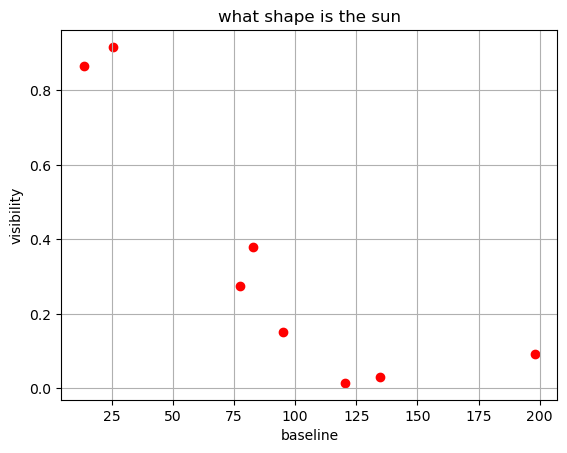

In [36]:
vis_list = [vis_A, vis_B, vis_C, vis_D, vis_E, vis_F, vis_G, vis_H]
B_list = [B_A, B_B, B_C, B_D, B_E, B_F, B_G, B_H]
print("list of visibilities (A-H): \n", vis_list)
print("list of B_values (A-H): \n", B_list)

plt.figure()
plt.scatter(B_list, vis_list, color='red')
plt.title(f"what shape is the sun")
plt.xlabel(f"baseline")
plt.ylabel(r"visibility")
plt.grid()
plt.show()

In [37]:
freq = ((11.21+11.29)/2) * 10**9 #avg freq from the observing range of the KRT
lambda1 = (3*10**8)/freq
FWHM = 4.9
D = 0.35 #m

sigma_B_A = (FWHM*D/(lambda1*avg_W_fringe_A**2)) * sigma_W_fringe_A
sigma_B_B = (FWHM*D/(lambda1*avg_W_fringe_B**2)) * sigma_W_fringe_B
sigma_B_C = (FWHM*D/(lambda1*avg_W_fringe_C**2)) * sigma_W_fringe_C
sigma_B_D = (FWHM*D/(lambda1*avg_W_fringe_D**2)) * sigma_W_fringe_D
sigma_B_E = (FWHM*D/(lambda1*avg_W_fringe_E**2)) * sigma_W_fringe_E
sigma_B_F = (FWHM*D/(lambda1*avg_W_fringe_F**2)) * sigma_W_fringe_F
sigma_B_G = (FWHM*D/(lambda1*avg_W_fringe_G**2)) * sigma_W_fringe_G
sigma_B_H = (FWHM*D/(lambda1*avg_W_fringe_H**2)) * sigma_W_fringe_H

In [38]:
sigma_B_list = [sigma_B_A, sigma_B_B, sigma_B_C, sigma_B_D, sigma_B_E, sigma_B_F, sigma_B_G, sigma_B_H]
print(sigma_B_list)


[1.157523918473136, 3.8207692543226575, nan, 2.6823376806863997, 3.2665614321173067, 1.4750815953638086, 1.1286290199085438, nan]


## Fitting functions

[82.72807339423254, 120.46182566205262, 25.548709942665585, 134.52454634210113, 198.03406609221614, 77.50409939074585, 94.91201229155551, 13.598686973071127]


/Software/users/modules/9/software/anaconda3/2024.02/lib/python3.11/site-packages/scipy/optimize/_minpack_py.py:1010: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


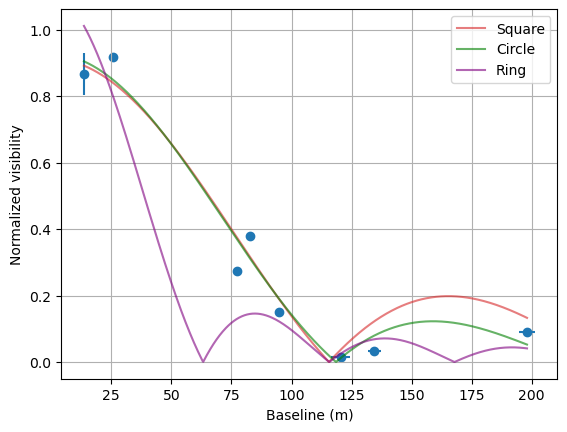

In [39]:
def V_square(B, a, b):
    V = a*np.abs(np.sinc(b*B))
    return V

def V_circle(B, a, b):
    V = np.abs(2*np.pi*a*b*jv(1, a*B)/B)
    return V

def V_disk(B, a1, b1, a2, b2):
    disk = V_circle(B, a1, b1) - V_circle(B, a2, b2)
    return disk

p0_square = [2, 0.005]
p0_circle = [0.001, 2]
p0_disk = [0.01, 2, 0.01, 0.001]

popt_square, pcov_square = curve_fit(V_square, B_list, vis_list, p0=p0_square)
p_err_square = np.sqrt(np.diag(pcov_square))
a_fit_square, b_fit_square = popt_square
a_err_square, b_err_square = p_err_square

popt_circle, pcov_circle = curve_fit(V_circle, B_list, vis_list, p0=p0_circle)
p_err_circle = np.sqrt(np.diag(pcov_circle))
a_fit_circle, b_fit_circle = popt_circle
a_err_circle, b_err_circle = p_err_circle

popt_disk, pcov_disk = curve_fit(V_disk, B_list, vis_list, p0=p0_disk)
p_err_disk = np.sqrt(np.diag(pcov_disk))
a1_fit_disk, b1_fit_disk, a2_fit_disk, b2_fit_disk = popt_disk
a1_err_disk, b1_err_disk, a2_err_disk, b2_err_disk = p_err_disk

B_smooth = np.linspace(min(B_list), max(B_list), 1000)
vis_list_err = [unc_vis_A, unc_vis_B, 0, unc_vis_D, unc_vis_E, unc_vis_F, unc_vis_G, unc_vis_H]

plt.figure()
plt.scatter(B_list, vis_list)
print(B_list)
plt.errorbar(B_list, vis_list, yerr=vis_list_err, xerr=sigma_B_list, fmt='None')
plt.plot(B_smooth, V_square(B_smooth, *popt_square), c='C3', alpha=0.6, label='Square')
plt.plot(B_smooth, V_circle(B_smooth, *popt_circle), color='green', alpha=0.6, label='Circle')
plt.plot(B_smooth, V_disk(B_smooth, *popt_disk), color='purple', alpha=0.6, label='Ring')
#plt.title(f"Various fits for shape of the Sun")
plt.ylabel(f"Normalized visibility")
plt.xlabel(r"Baseline (m)")
plt.legend()
plt.grid()
plt.show()

In [40]:
print(f"a1 = {popt_square[0]} ± {pcov_square[0,0]}, b1 = {popt_square[1]} ± {pcov_square[1,1]}")
print(f"a1 = {popt_circle[0]} ± {pcov_circle[0,0]}, b1 = {popt_circle[1]} ± {pcov_circle[1,1]}")
print(f"a1 = {popt_disk[0]} ± {pcov_disk[0,0]}, b1 = {popt_disk[1]} ± {pcov_disk[1,1]}, a2 = {popt_disk[2]} ± {pcov_disk[2,2]}, b2 = {popt_disk[3]} ± {pcov_disk[3,3]}")


a1 = 0.9122054057796142 ± 0.0027288281860056354, b1 = 0.008651382379379074 ± 1.0765286184975759e-07
a1 = 0.03232386700092656 ± 1.4454551300774898e-06, b1 = 282.3335761084261 ± 427.6076934748517
a1 = 0.060612307912837 ± inf, b1 = 95.48268749156573 ± inf, a2 = 8.971634062939556e-06 ± inf, b2 = -0.0013583802616613343 ± inf


In [41]:
#i want to find intersections with V = 0 line and these plots
B_dense = np.linspace(1e-6, max(B_list) * 2, 10000)
V_sq = a_fit_square * np.sinc(b_fit_square * B_dense)
V_cir = 2*np.pi*a_fit_circle*b_fit_circle*jv(1, a_fit_circle*B_dense) / B_dense
V_dis = 2*np.pi*a1_fit_disk*b1_fit_disk*jv(1, a1_fit_disk*B_dense) / B_dense - 2*np.pi*a2_fit_disk*b2_fit_disk*jv(1, a2_fit_disk*B_dense) / B_dense

def intersect(B, V, tol=1e-4):
    close_to_zero = np.where(np.abs(V) < tol)[0]
    if len(close_to_zero) == 0:
        return np.nan
    i = close_to_zero[0]
    if i == 0:
        return B[0]
    x1, x2 = B[i-1], B[i]
    y1, y2 = V[i-1], V[i]
    return x1 - y1 * (x2 - x1) / (y2 - y1)

B0_square = intersect(B_dense, V_sq)
B0_circle = intersect(B_dense, V_cir)
B0_disk = intersect(B_dense, V_dis)

print("Square B_0 = ", B0_square)
print("Circle B_0 = ", B0_circle)
print("Ring B_0 = ", B0_disk)


Square B_0 =  115.58846231733585
Circle B_0 =  118.54108039099377
Ring B_0 =  63.21663402378614


In [42]:
def ang_size(B0): #the result of this is in rad!
    return 1.22/(B0)

thet_sq = ang_size(B0_square)
thet_cir = ang_size(B0_circle)
thet_disk = 1/B0_disk

print("angular size for square: ", thet_sq)
print("angular size for circle: ", thet_cir)
print("angular size for ring: ", thet_disk)

angular size for square:  0.01055468664900671
angular size for circle:  0.010291790795022062
angular size for ring:  0.01581862140309046


In [43]:
def err_ang_size(B0, sigma_B):
    sig_theta = 1/(B0**2) * sigma_B
    return sig_theta
tol = 1e-4
err_theta_sq = err_ang_size(B0_square, tol)
print(err_theta_sq)
err_theta_cir = err_ang_size(B0_circle, tol)
print(err_theta_cir)
err_theta_dis = err_ang_size(B0_disk, tol)
print(err_theta_dis)

7.484641914721883e-09
7.116430916991459e-09
2.502287830943116e-08


In [44]:
def perc_error(ang_size):
    real = 0.0098902
    perc_err = np.abs((ang_size-real)/real) * 100
    return perc_err

perc_err_square = perc_error(thet_sq)
perc_err_circle = perc_error(thet_cir)
perc_err_disk = perc_error(thet_disk)

print("percentage error angular size for square: ", perc_err_square)
print("percentage error angular size for circle: ", perc_err_circle)
print("percentage error angular size for ring: ", perc_err_disk)

percentage error angular size for square:  6.718637125707367
percentage error angular size for circle:  4.060492154072338
percentage error angular size for ring:  59.942381378439855


In [45]:
B_array = np.array(B_list)
vis_array = np.array(vis_list)
N = len(vis_list)

def chi_square(y_obs, y_model, sigma=0.05):
    chi2 = np.sum(((y_obs - y_model)/sigma)**2)
    return chi2

V_sq = V_square(B_array, *popt_square)
V_cir = V_circle(B_array, *popt_circle)
V_dsk = V_disk(B_array, *popt_disk)

chi2_square = chi_square(vis_array, V_sq)
chi2_circle = chi_square(vis_array, V_cir)
chi2_disk = chi_square(vis_array, V_dsk)

red_square = chi2_square/(N - 2)
red_circle = chi2_circle/(N - 2)
red_disk = chi2_disk/(N - 4)

print(f"Square model: reduced chi^2 = {red_square:.3f}")
print(fr"Circle model: reduced chi^2 = {red_circle:.3f}")
print(fr"Disk model: reduced chi^2 = {red_disk:.3f}")

Square model: reduced chi^2 = 2.113
Circle model: reduced chi^2 = 1.609
Disk model: reduced chi^2 = 11.438
